In [1]:
import numpy as np
import torch as tc
import numpy.random as rd
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import argparse
import nonlinear_network

from circuit_solver import circuit as ct
from circuit_solver import elements as es
from circuit_solver import utils
from circuit_solver.learning import CoupledLearning, SymmetricCoupledLearning, CLTrainingConfig, CLTestingConfig
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'

# Note on $\eta$ convention

The convention used in the code base (`circuit-solver`) is that positive $\eta$ pushes the outputs towards the desired target state. In the paper, the opposite sign convention is used. This is the reason why the plots below have a mismatch between label and variable definition.

In [2]:
seed = 0    # RNG seed for model and data generation
tc_dtype = tc.float64
diode_lr = 1.       # set to zero to see violation of conservation.
N = 3
H = 3
M = 2
# eta_values = np.logspace(0, -3, 6)   # sweep eta from 1 down to 1e-3
eta_values = np.logspace(-3, -5, 5)  

N_eta = len(eta_values)
cb_ = [nonlinear_network.new(N=N, H=H, M=M, resistor_init_params=(1.,0.1), g_diode=1, diode_lr=diode_lr, seed=seed, dtype=tc_dtype) for _ in range(N_eta)]
for a in cb_:
    a.model.set_absorbing()

In [3]:
P = 100
x2_scale = 0.001
y_scale = 1000
dims = N
alpha_power = 1.0  # power-law exponent for eigenvalues: lambda_i ~ i^(-alpha)
eigenvalues = x2_scale * (np.arange(1, dims + 1, dtype=float)) ** (-alpha_power)

# Random orthogonal basis via QR
rng = np.random.default_rng(seed)
Q, _ = np.linalg.qr(rng.standard_normal((dims, dims)))
cov = Q @ np.diag(eigenvalues) @ Q.T
X = rng.multivariate_normal(np.zeros(dims), cov, size=P)
X_tc = tc.tensor(X, dtype=tc_dtype)

model = cb_[0].model
model.set_inputs('x')
Z_natural = model(X_tc)[0].detach().numpy()
y_inds = utils.nodes_to_inds(cb_[0].y_nodes, model.circuit)
Y = - y_scale * Z_natural[:, y_inds]                # push desired outputs hard in the other direction to encourage flips during clamping

X_data = X
Y_data = Y

In [4]:
# Train each network with coupled learning at the assigned eta values.

alpha = 0.01
N_batches = 2000
batch_size = P

histories = []
for cb, eta in zip(cb_, eta_values):
    cb.model.reset()
    config = CLTrainingConfig(
        batch_size=batch_size,
        N_batches=N_batches,
        alpha=alpha,
        eta=eta,
    )
    print(f"Training  eta={eta:.1e}")
    histories.append(CoupledLearning(X_data, Y_data, cb.model, config))

Training  eta=1.0e-03


100%|██████████| 2000/2000 [00:22<00:00, 89.51it/s] 


Training  eta=3.2e-04


100%|██████████| 2000/2000 [00:20<00:00, 97.72it/s]


Training  eta=1.0e-04


100%|██████████| 2000/2000 [00:20<00:00, 97.63it/s]


Training  eta=3.2e-05


100%|██████████| 2000/2000 [00:20<00:00, 95.48it/s]


Training  eta=1.0e-05


100%|██████████| 2000/2000 [00:20<00:00, 97.80it/s]


In [5]:
# Train fresh copies of the networks with symmetric coupled learning at the same eta values. Only the initial rate of
# change of K is needed, so the runs are short. Same seed, so every run starts from the same initialization as above.

N_batches_sym = 10

sym_histories = []
for eta in eta_values:
    cb = nonlinear_network.new(N=N, H=H, M=M, resistor_init_params=(1.,0.1), g_diode=10., diode_lr=1., seed=seed, dtype=tc_dtype)
    cb.model.set_absorbing()
    config = CLTrainingConfig(
        batch_size=batch_size,
        N_batches=N_batches_sym,
        alpha=alpha,
        eta=eta,
    )
    print(f"Training (symmetric)  eta={eta:.1e}")
    sym_histories.append(SymmetricCoupledLearning(X_data, Y_data, cb.model, config))

Training (symmetric)  eta=1.0e-03


100%|██████████| 10/10 [00:00<00:00, 58.16it/s]


Training (symmetric)  eta=3.2e-04


100%|██████████| 10/10 [00:00<00:00, 59.59it/s]


Training (symmetric)  eta=1.0e-04


100%|██████████| 10/10 [00:00<00:00, 58.69it/s]


Training (symmetric)  eta=3.2e-05


100%|██████████| 10/10 [00:00<00:00, 59.86it/s]


Training (symmetric)  eta=1.0e-05


100%|██████████| 10/10 [00:00<00:00, 58.22it/s]


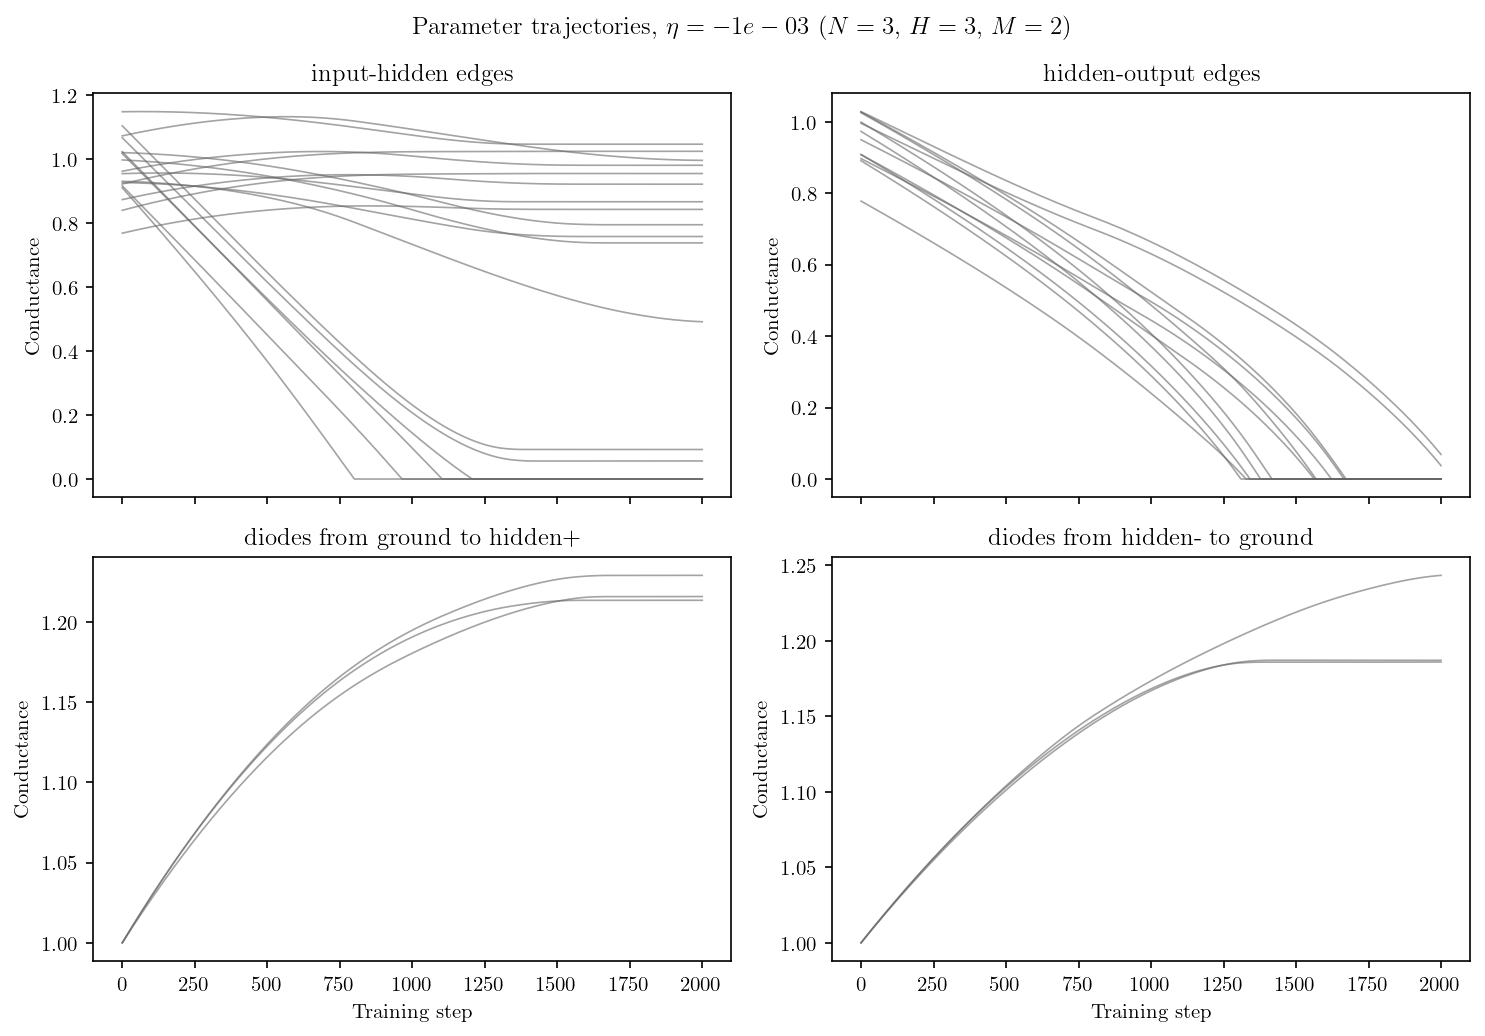

In [33]:
# Plot conductance trajectories for a single trial; change `trial` to look at other eta values.

trial = 0
history, eta = histories[trial], eta_values[trial]
layers = [('in', 'input-hidden edges'), ('out', 'hidden-output edges'), ('diode', 'diodes from ground to hidden+'), ('diode_neg', 'diodes from hidden- to ground')]

fig, axes = plt.subplots(2, 2, figsize=(10, 7), dpi=150, sharex=True)
for ax, (key, label) in zip(axes.flat, layers):
    G = history[key][0]   # shape (N_batches+1, N_edges)
    ax.plot(np.arange(G.shape[0]), G, linewidth=0.8, alpha=0.6, color=(0.4, 0.4, 0.4))
    ax.set_title(label)
    ax.set_ylabel('Conductance')
for ax in axes[-1]:
    ax.set_xlabel('Training step')

fig.suptitle(f'Parameter trajectories, $\\eta = {-eta:.0e}$  ($N={N}$, $H={H}$, $M={M}$)')
plt.tight_layout()
plt.show()

# Convergence for $\eta \to 0$

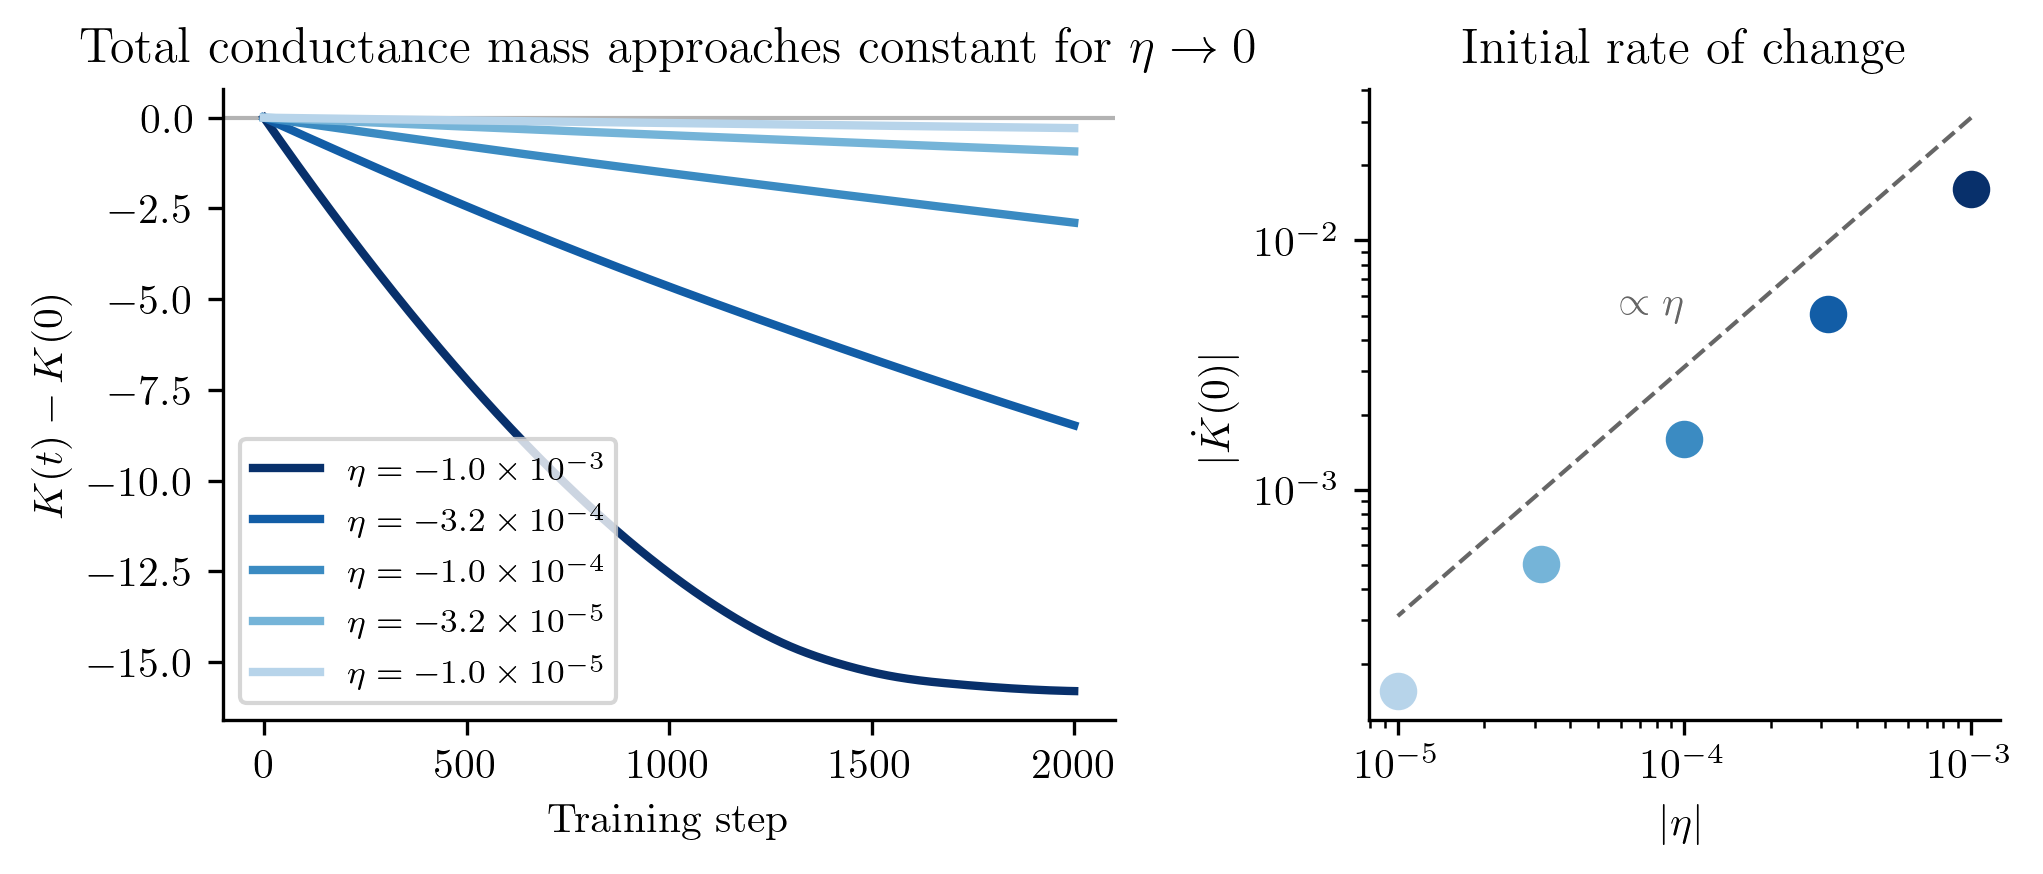

In [30]:
# Total conductance mass K(t): sum of squared conductances over all edges, including the ideal diodes.
# Every trial starts from the same initialization, so curves are shown as the change from K(0).

mass_layers = ['in', 'out', 'diode', 'diode_neg']

def conductance_mass(histories):
    """K for every trial and training step, shape [trial, step]."""
    return np.array([sum(np.sum(history[key]**2, axis=(0, 2)) for key in mass_layers) for history in histories])

def eta_colors(eta_values):
    """Sequential single-hue colormap on a log scale: darker = larger eta."""
    norm = mpl.colors.LogNorm(vmin=min(eta_values), vmax=max(eta_values))
    cmap = mpl.colors.LinearSegmentedColormap.from_list('eta', plt.cm.Blues(np.linspace(0.3, 1., 256)))
    return cmap, norm

def sci_label(x):
    mantissa, exponent = f'{x:.1e}'.split('e')
    power = f'10^{{{int(exponent)}}}'
    return power if mantissa == '1.0' else f'{mantissa} \\times {power}'

def plot_mass_change(ax, K, eta_values):
    """K(t) - K(0) against training step, one curve per eta."""
    cmap, norm = eta_colors(eta_values)
    steps = np.arange(K.shape[1])
    ax.axhline(0, color=(0.7, 0.7, 0.7), linewidth=1, zorder=0)
    for k, eta in zip(K, eta_values):
        ax.plot(steps, k - k[0], linewidth=2, color=cmap(norm(eta)), label=f'$\\eta = {sci_label(-eta)}$')
    ax.legend(frameon=True, fontsize=8)
    ax.set_xlabel('Training step')
    ax.set_ylabel(r'$K(t) - K(0)$')
    ax.set_title(r'Total conductance mass approaches constant for $\eta\to 0$')
    ax.spines[['top', 'right']].set_visible(False)

def plot_initial_rate(ax, K, eta_values, ref_scale=2, K_sym=None, ref_scale_sym=5):
    """|K'(0)| (first-step change in K) against eta on a square loglog panel, with an O(eta) reference line drawn
    ref_scale times above the smallest-eta point. If K_sym (symmetric coupled learning) is given, it is drawn with
    squares, with an O(eta^2) reference line drawn ref_scale_sym times above its smallest-eta point."""
    cmap, norm = eta_colors(eta_values)
    i_ref = np.argmin(eta_values)
    eta_mid = np.sqrt(min(eta_values) * max(eta_values))   # reference labels at the middle of each line, just above it
    series = [(K, 'o', 1, ref_scale, r'$\propto \eta$')]
    if K_sym is not None:
        series.append((K_sym, 's', 2, ref_scale_sym, r'$\propto \eta^2$'))
    for K_i, marker, power, scale, ref_label in series:
        K_dot_0 = np.abs(K_i[:, 1] - K_i[:, 0])
        for eta, kd in zip(eta_values, K_dot_0):
            ax.loglog(eta, kd, marker, markersize=8, color=cmap(norm(eta)))
        ref_line = scale * K_dot_0[i_ref] * (eta_values / eta_values[i_ref])**power
        ax.loglog(eta_values, ref_line, '--', color=(0.4, 0.4, 0.4), linewidth=1, zorder=0)
        ax.text(eta_mid, 1.5 * scale * K_dot_0[i_ref] * (eta_mid / eta_values[i_ref])**power, ref_label,
                ha='right', va='bottom', color=(0.4, 0.4, 0.4))
    if K_sym is not None:
        handles = [mpl.lines.Line2D([], [], marker=m, linestyle='none', markersize=8, color=(0.4, 0.4, 0.4), label=l)
                   for m, l in [('o', 'CL'), ('s', 'Symmetric CL')]]
        ax.legend(handles=handles, frameon=False)
    ax.set_box_aspect(1)
    ax.set_xlabel(r'$|\eta|$')
    ax.set_ylabel(r'$|\dot{K}(0)|$')
    ax.set_title('Initial rate of change')
    ax.spines[['top', 'right']].set_visible(False)

K = conductance_mass(histories)
K_sym = conductance_mass(sym_histories)

fig, (ax, ax_rate) = plt.subplots(1, 2, figsize=(7, 3), dpi=300, gridspec_kw={'width_ratios': [1.3, 1]})
plot_mass_change(ax, K, eta_values)
# plot_initial_rate(ax_rate, K, eta_values, K_sym=K_sym)
plot_initial_rate(ax_rate, K, eta_values)
plt.tight_layout()
plt.show()

# Cartoon

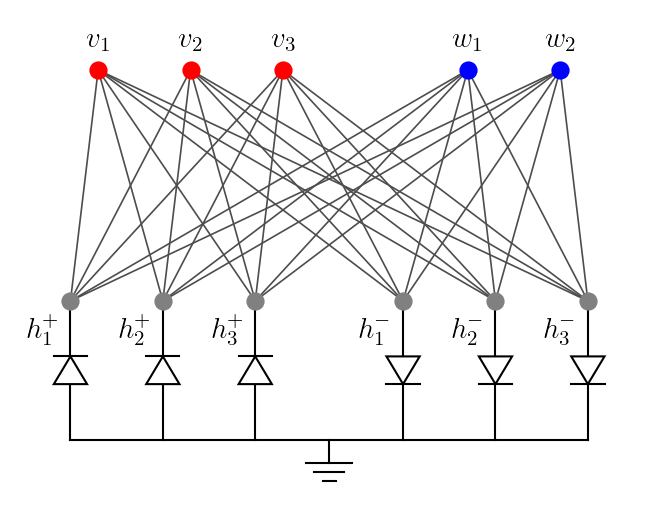

In [31]:
# Cartoon of the network topology, in the style of crossbar.tex. Resistors are plain lines; the ideal diodes point
# along their edge direction (GROUND -> h+ and h- -> GROUND). All diodes share the single ground node, drawn as a rail.
# Drawn with matplotlib so the labels are typeset by LaTeX (text.usetex is set above).

edge_kw = dict(color=(0.3, 0.3, 0.3), linewidth=0.8, zorder=1)   # thin, black!70
wire_kw = dict(color='black', linewidth=1.0, zorder=2)

def draw_diode(ax, x, yc, up):
    # triangle points from anode to cathode; the bar marks the cathode
    s, w = (1 if up else -1) * 0.15, 0.18
    ax.add_patch(mpl.patches.Polygon([(x - w, yc - s), (x + w, yc - s), (x, yc + s)], closed=True,
                                     facecolor='white', edgecolor='black', linewidth=1.0, zorder=3))
    ax.plot([x - w, x + w], [yc + s, yc + s], **wire_kw)

def draw_topology(ax, N, H, M, group_gap=0.6, io_gap=1.0, fontsize=14):
    """Draw the network on ax in tikz-like units (y up) with equal aspect; group_gap is the extra space between the
    h+ and h- groups, io_gap the extra space between the inputs and outputs."""
    # Hidden nodes sit in a row (h+ group, gap, h- group); inputs and outputs share a row above it (inputs, gap,
    # outputs), so the diodes hang straight down to the ground rail without crossing any edges.
    y_top = 2.5
    h_pos = [(k, 0.) for k in range(H)]
    h_neg_pos = [(H + group_gap + k, 0.) for k in range(H)]
    hidden = h_pos + h_neg_pos
    x_mid = (hidden[0][0] + hidden[-1][0]) / 2
    top_left = x_mid - (N + M - 1 + io_gap) / 2   # centre the top row over the hidden row
    x_pos = [(top_left + i, y_top) for i in range(N)]
    y_pos = [(top_left + N + io_gap + j, y_top) for j in range(M)]
    y_rail, y_diode = -1.5, -0.75

    # resistor edges: input -> every hidden node, every hidden node -> output
    for a in x_pos:
        for b in hidden:
            ax.plot([a[0], b[0]], [a[1], b[1]], **edge_kw)
    for a in hidden:
        for b in y_pos:
            ax.plot([a[0], b[0]], [a[1], b[1]], **edge_kw)

    # diodes down to the ground rail, then one ground symbol
    for hx, _ in hidden:
        ax.plot([hx, hx], [0., y_rail], **wire_kw)
    for hx, _ in h_pos:
        draw_diode(ax, hx, y_diode, up=True)
    for hx, _ in h_neg_pos:
        draw_diode(ax, hx, y_diode, up=False)
    ax.plot([hidden[0][0], hidden[-1][0]], [y_rail, y_rail], **wire_kw)
    ax.plot([x_mid, x_mid], [y_rail, y_rail - 0.25], **wire_kw)
    for w, d in [(0.25, 0.), (0.16, 0.1), (0.07, 0.2)]:
        ax.plot([x_mid - w, x_mid + w], [y_rail - 0.25 - d] * 2, **wire_kw)

    # nodes: inputs red, hidden gray, outputs blue
    for pos, color in [(x_pos, 'red'), (hidden, 'gray'), (y_pos, 'blue')]:
        ax.scatter(*zip(*pos), s=60, color=color, zorder=4)

    # labels
    for i, (x, y) in enumerate(x_pos):
        ax.text(x, y + 0.2, f'$v_{{{i + 1}}}$', ha='center', va='bottom', fontsize=fontsize)
    for j, (x, y) in enumerate(y_pos):
        ax.text(x, y + 0.2, f'$w_{{{j + 1}}}$', ha='center', va='bottom', fontsize=fontsize)
    for k, (x, _) in enumerate(h_pos):
        ax.text(x - 0.12, -0.3, f'$h_{{{k + 1}}}^+$', ha='right', va='center', fontsize=fontsize)
    for k, (x, _) in enumerate(h_neg_pos):
        ax.text(x - 0.12, -0.3, f'$h_{{{k + 1}}}^-$', ha='right', va='center', fontsize=fontsize)

    margin = 0.6
    ax.set_xlim(min(x_pos[0][0], hidden[0][0]) - margin, max(y_pos[-1][0], hidden[-1][0]) + margin)
    ax.set_ylim(y_rail - 0.6, y_top + margin)
    ax.set_aspect('equal')
    # ax.set_title('Circuit layout')
    ax.axis('off')

scale = 0.8   # inches per unit
fig, ax = plt.subplots(dpi=150)
draw_topology(ax, N, H, M)
(x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
fig.set_size_inches((x1 - x0) * scale, (y1 - y0) * scale)
fig.savefig('nonlinear_network_topology.svg', bbox_inches='tight')
plt.show()

# Figure

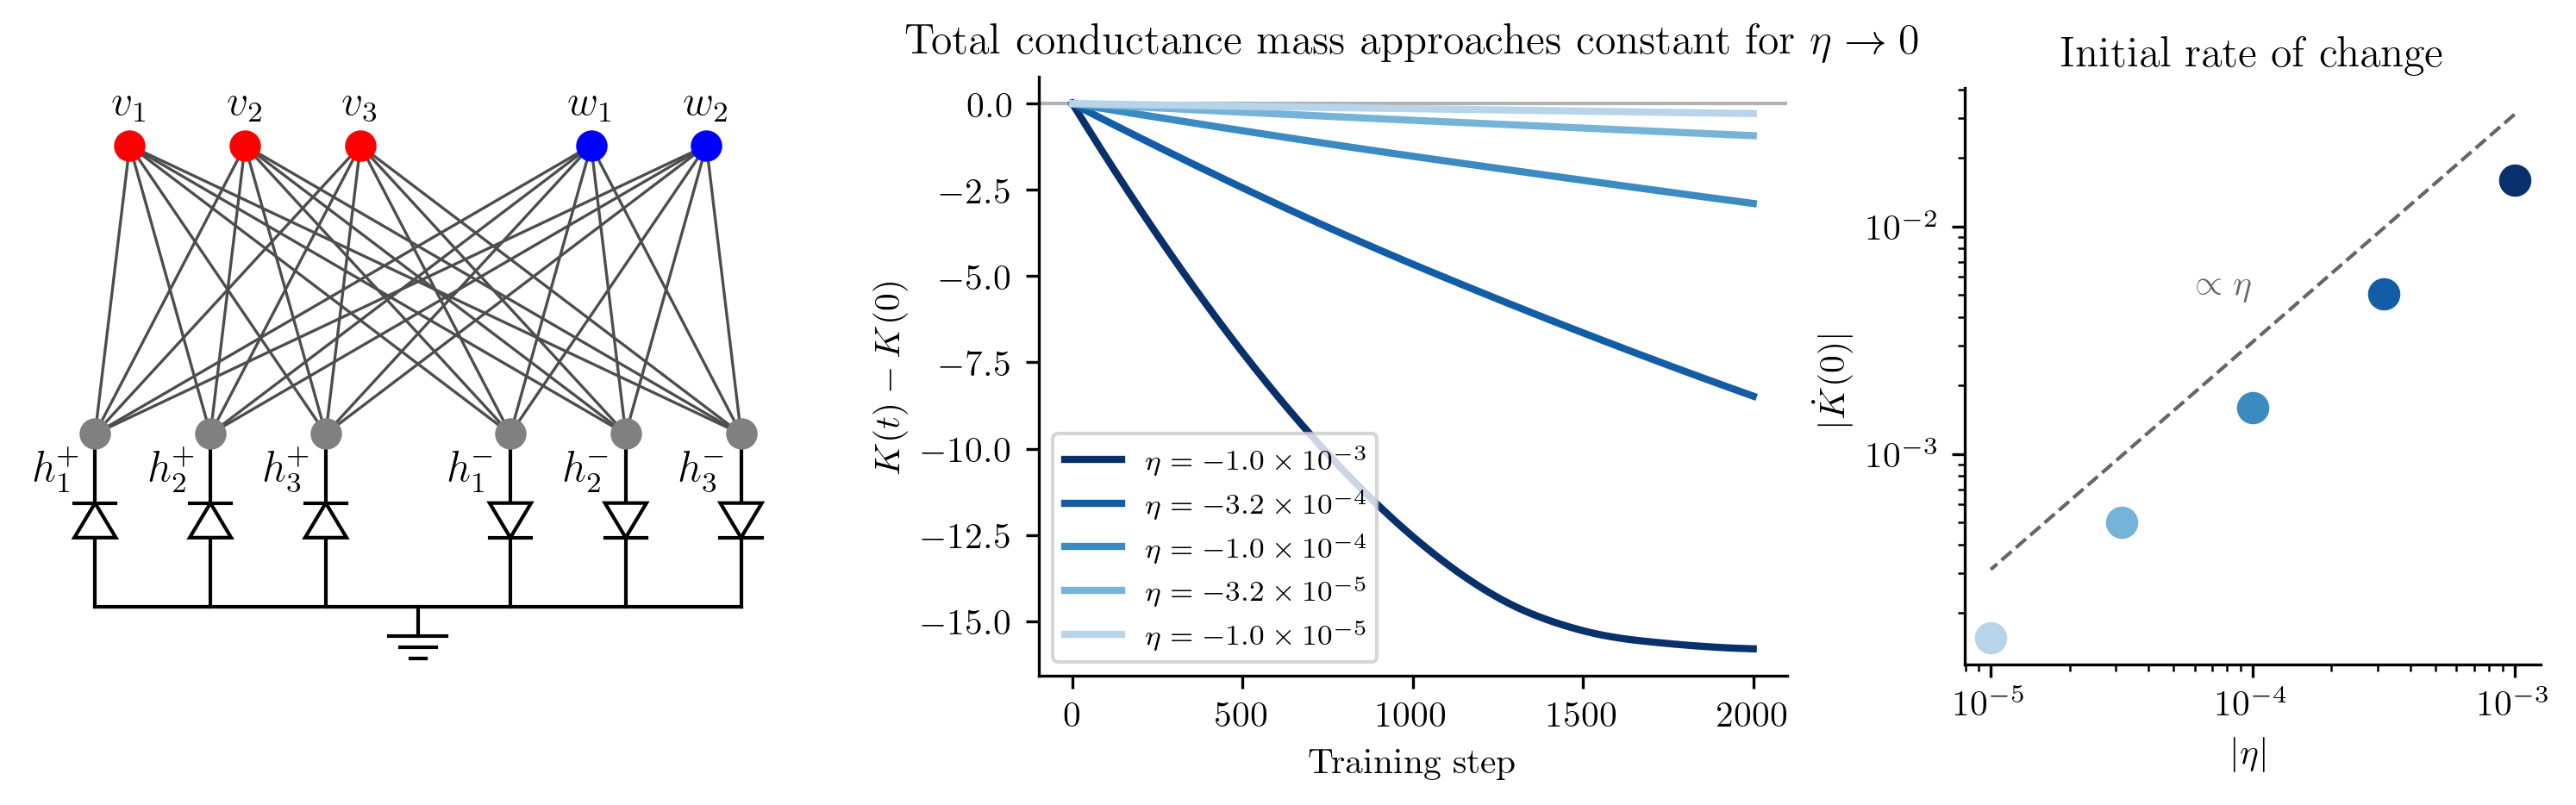

In [32]:
# All panels in one row: network cartoon, change in conductance mass, and initial rate of change against eta.

fig, (ax_net, ax_mass, ax_rate) = plt.subplots(1, 3, figsize=(10, 3), dpi=300, layout='constrained',
                                               gridspec_kw={'width_ratios': [1.5, 1.3, 1]})
draw_topology(ax_net, N, H, M, fontsize=12)
plot_mass_change(ax_mass, K, eta_values)
# plot_initial_rate(ax_rate, K, eta_values, K_sym=K_sym)
plot_initial_rate(ax_rate, K, eta_values)
plt.show()

# Diode switching under clamping

In [10]:
# Are diodes tripped by clamping? Replay each CL run: at every `stride`-th training step, load that step's parameters,
# solve the free and clamped states on the full data set exactly as CoupledLearning does, and count the diodes whose
# voltage drop has opposite signs in the two states.

from circuit_solver.learning import clamping_functions

stride = 1
diode_layers = ['diode', 'diode_neg']

def diode_sign_flips(history, eta, steps):
    """Mean number of diodes per sample whose voltage drop changes sign between the free and clamped states,
    using the parameters before each of the given training steps."""
    model = nonlinear_network.new(N=N, H=H, M=M, resistor_init_params=(1.,0.1), g_diode=10., diode_lr=1., seed=seed, dtype=tc_dtype).model
    cfg = CLTrainingConfig(batch_size=batch_size, N_batches=N_batches, alpha=alpha, eta=eta)
    clamp = clamping_functions[cfg.clamp_method]
    x_nodes, y_nodes = model.node_type_dict[cfg.x_nodes], model.node_type_dict[cfg.y_nodes]
    y_inds = utils.nodes_to_inds(y_nodes, model.circuit)
    diode_inds = [i for name in diode_layers for i in model.element_to_inds[name]]
    x = tc.as_tensor(X_data, dtype=model.dtype)
    y = tc.as_tensor(Y_data, dtype=model.dtype)

    flips = np.zeros(len(steps))
    for i, t in enumerate(steps):
        for name, layer in model.element_layers.items():
            layer.theta.data.copy_(tc.as_tensor(history[name][:, t]))
        model.set_inputs(x_nodes)
        V_node_F, _ = model(x)
        V_F = model.V_edge()[:, diode_inds].detach()
        model.set_inputs(x_nodes, y_nodes)
        model(x, clamp(y, V_node_F[:, y_inds].detach(), cfg))
        V_C = model.V_edge()[:, diode_inds].detach()
        flips[i] = (tc.sign(V_F) != tc.sign(V_C)).sum(dim=1).double().mean().item()
    return flips

flip_steps = np.arange(0, N_batches, stride)
diode_flips = []
for history, eta in zip(histories, eta_values):
    print(f"Replaying  eta={eta:.1e}")
    diode_flips.append(diode_sign_flips(history, eta, flip_steps))


Replaying  eta=1.0e-03
Replaying  eta=3.2e-04
Replaying  eta=1.0e-04
Replaying  eta=3.2e-05
Replaying  eta=1.0e-05


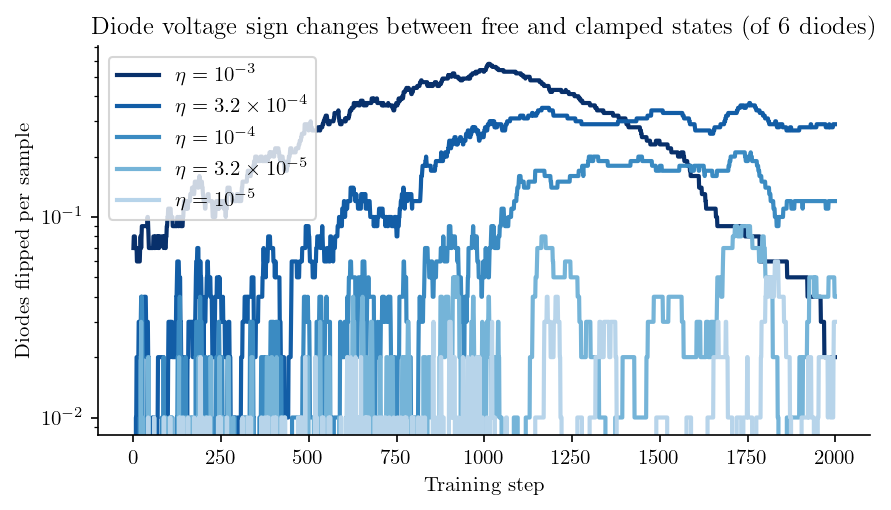

In [22]:
cmap, norm = eta_colors(eta_values)
fig, ax = plt.subplots(figsize=(6, 3.5), dpi=150)
for flips, eta in zip(diode_flips, eta_values):
    ax.semilogy(flip_steps, flips, linewidth=2, color=cmap(norm(eta)), label=f'$\\eta = {sci_label(eta)}$')
    # ax.text()
ax.legend(frameon=True, loc='upper left')
ax.set_xlabel('Training step')
ax.set_ylabel('Diodes flipped per sample')
ax.set_title(f'Diode voltage sign changes between free and clamped states (of {2 * H} diodes)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# Step-size sweep

In [12]:
# Train at a small eta while taking alpha -> 0, holding the total training time alpha * N_batches fixed.

eta_small = 1e-4
T_train = alpha * N_batches                              # alpha * N_batches, the same for every trial
alpha_values = 2. ** (np.arange(6)-1) * alpha   

alpha_histories = []
for alpha_i in alpha_values:
    cb = nonlinear_network.new(N=N, H=H, M=M, resistor_init_params=(1.,0.1), g_diode=10., diode_lr=1., seed=seed)
    cb.model.set_absorbing()
    config = CLTrainingConfig(
        batch_size=batch_size,
        N_batches=int(round(T_train / alpha_i)),
        alpha=alpha_i,
        eta=eta_small,
    )
    print(f"Training  alpha={alpha_i:.2e}  N_batches={config.N_batches}")
    alpha_histories.append(CoupledLearning(X_data, Y_data, cb.model, config))

Training  alpha=5.00e-03  N_batches=4000


100%|██████████| 4000/4000 [00:54<00:00, 72.89it/s]


Training  alpha=1.00e-02  N_batches=2000


100%|██████████| 2000/2000 [00:27<00:00, 72.69it/s]


Training  alpha=2.00e-02  N_batches=1000


...

100%|██████████| 500/500 [00:06<00:00, 74.29it/s]


Training  alpha=8.00e-02  N_batches=250


100%|██████████| 250/250 [00:03<00:00, 74.42it/s]


Training  alpha=1.60e-01  N_batches=125


100%|██████████| 125/125 [00:01<00:00, 73.48it/s]


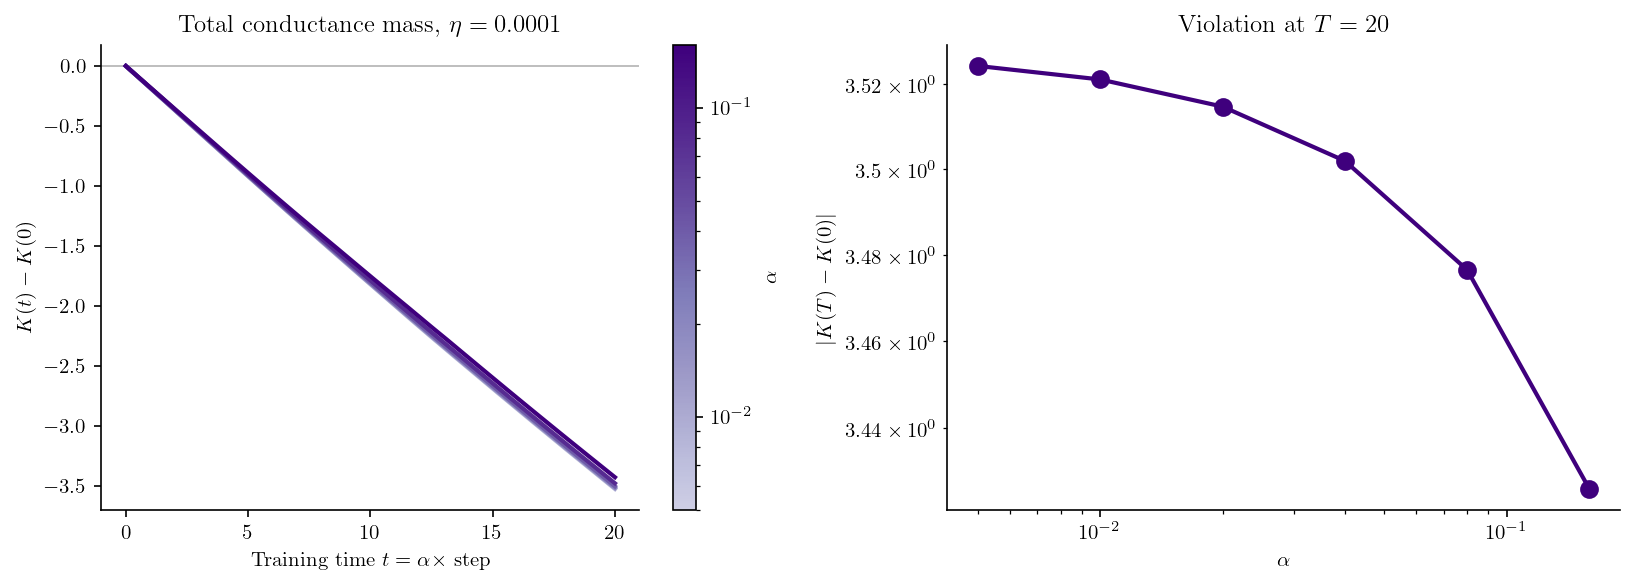

In [13]:
# Left: change in total conductance mass against training time t = alpha * step, one curve per alpha.
# Right: the violation at the end of training against alpha.

K_alpha = [sum(np.sum(history[key]**2, axis=(0, 2)) for key in mass_layers) for history in alpha_histories]   # one array per alpha (lengths differ)

# sequential single-hue colormap on a log scale: darker = larger alpha
norm = mpl.colors.LogNorm(vmin=min(alpha_values), vmax=max(alpha_values))
cmap = mpl.colors.LinearSegmentedColormap.from_list('alpha', plt.cm.Purples(np.linspace(0.3, 1., 256)))

fig, (ax, ax_end) = plt.subplots(1, 2, figsize=(11, 4), dpi=150)

ax.axhline(0, color=(0.7, 0.7, 0.7), linewidth=0.8, zorder=0)
for k, alpha_i in zip(K_alpha, alpha_values):
    ax.plot(alpha_i * np.arange(len(k)), k - k[0], linewidth=2, color=cmap(norm(alpha_i)))
fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=r'$\alpha$')
ax.set_xlabel(r'Training time $t = \alpha \times$ step')
ax.set_ylabel(r'$K(t) - K(0)$')
ax.set_title(f'Total conductance mass, $\\eta = {eta_small:g}$')

violation = [abs(k[-1] - k[0]) for k in K_alpha]
ax_end.loglog(alpha_values, violation, 'o-', linewidth=2, markersize=8, color=cmap(1.))
ax_end.set_xlabel(r'$\alpha$')
ax_end.set_ylabel(r'$|K(T) - K(0)|$')
ax_end.set_title(f'Violation at $T = {T_train:g}$')

for a in (ax, ax_end):
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()